# MVP first run: demographics-only supervised baselines

This notebook documents the first complete run of the MVP pipeline in `src/sdt/mvp/`. The models see only respondent
attributes, which is the demographics-only rung of the information ladder. The notebook covers three things in order:
how the raw survey file becomes model inputs, how predictions are scored, and the two supervised models that were
trained and evaluated. It is a guide to the infrastructure, not a test of the research question, which needs state
variables and the twins.

Results are read from `experiments/mvp/demographics/`, written by `python -m sdt.mvp.run demographics`. The only
model fitted here is the multinomial logit, refitted to display its coefficients.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sdt.mvp.clean import CLASSES, FIRST_MONTH, INPUTS, OUT_PATH, OUTCOMES, load_raw
from sdt.mvp.encode import gb_features, mnl_features
from sdt.mvp.models import mnl
from sdt.mvp.run import EXPERIMENTS
from sdt.mvp.score import item_data
from sdt.mvp.windows import EVAL_START, TRAIN_END, split
pd.set_option('display.max_columns', None); pd.set_option('display.width', None)
MISSING = '#fde2c8'

clean = pd.read_parquet(OUT_PATH)
RUN = EXPERIMENTS / 'demographics'
scores = pd.read_csv(RUN / 'scores.csv')
settings = json.load(open(RUN / 'gb_settings.json'))
pred = pd.read_parquet(RUN / 'predictions.parquet')
meta = json.load(open(RUN / 'run.json'))
print(f"Run of {meta['date']} at commit {meta['commit'][:7]}, data.csv SHA-256 {meta['data_csv_sha256'][:12]}...")

Run of 2026-10-22 at commit 6294d51, data.csv SHA-256 5e0a7e1cd2a0...


## 1. From raw file to model inputs

Two steps turn the raw survey file into model inputs. `clean.py` reads `data/data.csv` and writes one clean table,
`data/processed/mvp_clean.parquet`, with one row per interview. `encode.py` then turns the clean table into features,
in a different form for each model family. The clean table covers February 2017 to February 2026, 77,050 interviews. It
starts in February 2017 because that is when the party question began to be asked every month. It keeps three groups
of columns:

- **Outcomes:** the five items of the Index of Consumer Sentiment, `PAGO`, `PEXP`, `BUS12`, `BUS5` and `DUR`.
- **Inputs:** the eleven respondent attributes chosen in notebook 02: income quintile (`YTL5`), home and stock
  ownership (`HOMEOWN`, `INVEST`), age (`AGE`), region (`REGION`), sex (`SEX`), marital status (`MARRY`), children and
  adults in the household (`NUMKID`, `NUMADT`), education (`EDUC`) and party (`POLAFF`).
- **Design columns:** the case ID, the survey month, the weight `WT`, the survey mode `METHOD`, and the panel links
  `ID`, `IDPREV` and `DATEPR`. This run does not use the panel links; a later study can use them to add a respondent's
  previous answers.

The tables below follow five interviews through every step, chosen to cover the main cases. Missing values are shaded.

In [2]:
raw = load_raw()
raw = raw[raw.YYYYMM >= FIRST_MONTH].set_index('CASEID')
cases = {
    'phone, complete': (raw.METHOD == 1) & raw[INPUTS].notna().all(axis=1) & (raw[list(OUTCOMES)] < 8).all(axis=1),
    'web, blank demographics, party NA': (raw.METHOD == 2) & raw.AGE.isna() & raw.SEX.isna() & (raw.POLAFF == 9),
    'web, adults in household coded 9': (raw.METHOD == 2) & (raw.NUMADT == 9) & raw.POLAFF.isin([1, 2]),
    'phone, "with qualifications" and DK': (raw.BUS12 == 2) & (raw.PEXP == 8),
    'phone, lowest education code': (raw.BUS5 == 4) & (raw.EDUC == 1),
}
ids = [raw[m].sample(1, random_state=0).index[0] for m in cases.values()]
example = pd.Series(list(cases), index=pd.Index(ids, name='CASEID'), name='case')
example.to_frame()

,case
CASEID,
296239,"phone, complete"
321940,"web, blank demographics, party NA"
341248,"web, adults in household coded 9"
265873,"phone, ""with qualifications"" and DK"
288836,"phone, lowest education code"


### 1.1 Raw

Michigan stores every answer as a numeric code.

- **Outcomes** code the favourable answer 1, the middle answer 3 and the unfavourable answer 5. `BUS12` and `BUS5` also
  use 2 and 4 for "good with qualifications" and "bad with qualifications", which only phone interviewers record.
- **Missing answers** are either blank or coded. The outcomes and `POLAFF` use 8 for don't know and 9 for not
  ascertained (98 and 99 for `BUS5`). `HOMEOWN` uses 99 for not ascertained, and `NUMADT` uses 8 and 9, which the
  codebook leaves unlabelled. On the web, `NUMADT` left missing values blank until November 2024 and coded them 9
  afterwards.
- **Some codes cover more than one answer.** `INVEST` has no missing code, because its code 5 pools "no", "don't know"
  and "not ascertained". `AGE` 97 means 97 or older, and `NUMKID` and `NUMADT` stop at 5.
- **`METHOD`** is 1 for telephone and 2 for web.

In [3]:
COLS = ['YYYYMM', 'WT'] + list(OUTCOMES) + ['YTL5', 'HOMEOWN', 'INVEST', 'AGE', 'REGION', 'SEX', 'MARRY', 'NUMKID',
                                           'NUMADT', 'EDUC', 'POLAFF']
raw.loc[ids, ['METHOD'] + COLS].style.highlight_null(color=MISSING).format(precision=0, na_rep='').format(
    precision=2, subset=['WT'])

,METHOD,YYYYMM,WT,PAGO,PEXP,BUS12,BUS5,DUR,YTL5,HOMEOWN,INVEST,AGE,REGION,SEX,MARRY,NUMKID,NUMADT,EDUC,POLAFF
CASEID,,,,,,,,,,,,,,,,,,,
296239,1,202104,0.75,1,3,5,4,5,2,1,1,68,2,2,1,0,2,3,1
321940,2,202408,0.41,5,1,1,3,5,2,1,5,,4,,,,,,9
341248,2,202602,2.23,3,3,3,3,5,1,99,5,,1,,,,9,4,2
265873,1,201702,0.75,1,8,2,1,1,3,1,1,73,4,1,1,0,3,6,1
288836,1,202004,1.50,5,3,5,4,5,1,1,5,69,4,2,1,0,2,1,3


### 1.2 Clean

Cleaning maps every raw code to a clean value. A code with no mapping stops the cleaning with an error, so a new code in
a later download cannot pass through unnoticed.

- **Outcomes** become favourable (1, 2), middle (3) or unfavourable (4, 5), written `fav`, `mid` and `unf`. An
  interview with a missing outcome stays in the table and is left out only of that item's model. The three classes are
  kept even though the share of middle answers depends on the survey mode; section 3.1 shows how the web indicator
  absorbs that shift.
- **Ordered inputs** stay integers: `YTL5` 1-5, `AGE` 18-97, `NUMKID` 0-5 and `NUMADT` 1-5. `EDUC` is renumbered 1-5
  after merging its two rare lowest codes into 1, "no high school diploma".
- **Unordered inputs** become labels: `HOMEOWN` own or rent; `REGION` West (W), North Central (NC), Northeast (NE) or
  South (S); `SEX` male or female; `MARRY` married, divorced, widowed or never married; `POLAFF` Republican (Rep),
  Democrat (Dem) or independent (Ind).
- **Binary columns** become 0/1: `INVEST` is 1 if the household holds stocks, and `web` is 1 for a web interview.
- **Missing values** become NaN, whatever their raw code.

Nothing is imputed. The models must predict every evaluation respondent, and blanks are not spread at random: about a
tenth of web respondents leave their demographics blank, against almost no phone respondents, and every evaluation
interview is web. So a missing value stays missing, and each model learns from it directly, as sections 1.3 and 1.4
describe.

In [4]:
c = clean.set_index('CASEID').loc[ids]
c[['web'] + COLS].style.highlight_null(color=MISSING).format(na_rep='NaN', precision=2)

,web,YYYYMM,WT,PAGO,PEXP,BUS12,BUS5,DUR,YTL5,HOMEOWN,INVEST,AGE,REGION,SEX,MARRY,NUMKID,NUMADT,EDUC,POLAFF
CASEID,,,,,,,,,,,,,,,,,,,
296239,0,202104,0.75,fav,mid,unf,unf,unf,2,own,1,68,NC,female,married,0,2,2,Rep
321940,1,202408,0.41,unf,fav,fav,mid,unf,2,own,0,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN
341248,1,202602,2.23,mid,mid,mid,mid,unf,1,NaN,0,NaN,W,NaN,NaN,NaN,NaN,3,Dem
265873,0,201702,0.75,fav,NaN,fav,fav,fav,3,own,1,73,S,male,married,0,3,5,Rep
288836,0,202004,1.50,unf,mid,unf,unf,unf,1,own,0,69,S,female,married,0,2,1,Ind


### 1.3 Encoded for the multinomial logit

The logit is linear in its inputs, so an input with several levels becomes one 0/1 column per level, which lets each
level have its own effect. Three rules produce the 39 columns:

1. `AGE`, `NUMKID` and `NUMADT` are first grouped into bands: ages 18-34, 35-49, 50-64, 65-74 and 75+; 0, 1, 2 and 3+
   children; 1, 2, 3 and 4+ adults.
2. Each input's most common level is dropped as the reference. An interview at that level has zeros in all of the
   input's columns, and each coefficient compares a level with the reference. The references are the top income
   quintile, owners, ages 50-64, the South, men, married, no children, two adults, a bachelor's degree (`EDUC` 4) and
   independents.
3. Missing values get a column of their own, ending in `=NR` (not reported), for every input except `REGION`, which is
   never missing.

`INVEST` and `web` enter as they are. The outcomes are what the model predicts, so they are not features.

In [5]:
X = mnl_features(c)
X.style.format('{:.0f}').map(lambda v: 'background-color: #d6e6fa' if v == 1 else 'color: #c3c2b7') \
    .map(lambda v: f'background-color: {MISSING}' if v == 1 else '', subset=[k for k in X if k.endswith('=NR')])

,YTL5=1,YTL5=2,YTL5=3,YTL5=4,YTL5=NR,HOMEOWN=rent,HOMEOWN=NR,INVEST,AGE=18-34,AGE=35-49,AGE=65-74,AGE=75+,AGE=NR,REGION=W,REGION=NC,REGION=NE,SEX=female,SEX=NR,MARRY=divorced,MARRY=widowed,MARRY=never,MARRY=NR,NUMKID=1,NUMKID=2,NUMKID=3+,NUMKID=NR,NUMADT=1,NUMADT=3,NUMADT=4+,NUMADT=NR,EDUC=1,EDUC=2,EDUC=3,EDUC=5,EDUC=NR,POLAFF=Rep,POLAFF=Dem,POLAFF=NR,web
CASEID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
296239,0,1,0,0,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0
321940,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,1
341248,1,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,1
265873,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0
288836,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0


### 1.4 Encoded for gradient boosting

Trees split on thresholds, so ordered inputs can stay numbers: a split such as `AGE` ≤ 49 uses their order without
assuming equal steps between levels. The five ordered inputs (`YTL5`, `AGE`, `NUMKID`, `NUMADT`, `EDUC`) are passed as
numbers, and the five unordered inputs (`HOMEOWN`, `REGION`, `SEX`, `MARRY`, `POLAFF`) as categories, which a split can
group, for example Democrats against everyone else. The category levels are fixed in the code rather than read from the
data. `INVEST` and `web` enter as 0/1. Missing values stay NaN, and at each split the tree learns which side they go
to. The result is 12 columns.

In [6]:
gb_features(c).style.highlight_null(color=MISSING).format(precision=0, na_rep='NaN')

,YTL5,HOMEOWN,INVEST,AGE,REGION,SEX,MARRY,NUMKID,NUMADT,EDUC,POLAFF,web
CASEID,,,,,,,,,,,,
296239,2,own,1,68,NC,female,married,0,2,2,Rep,0
321940,2,own,0,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN,1
341248,1,NaN,0,NaN,W,NaN,NaN,NaN,NaN,3,Dem,1
265873,3,own,1,73,S,male,married,0,3,5,Rep,0
288836,1,own,0,69,S,female,married,0,2,1,Ind,0


## 2. Scoring

### 2.1 Training and evaluation windows

Every model is fit on interviews from February 2017 to July 2024 and scored on interviews from August 2024 to
February 2026. Training ends with the last interview window that closed before Llama 3.1 was released on 23 July 2024,
so the twins evaluated later face the same split. Every evaluation interview is web. Training is phone except for the
web interviews of April to July 2024. Each model is fit separately for each of the five items, on the interviews that
answered that item.

In [7]:
train, test = split(clean)
pd.DataFrame({item: {'train': train[item].notna().sum(), 'of which web': (train[item].notna() & (train.web == 1)).sum(),
                     'evaluate': test[item].notna().sum()} for item in OUTCOMES}).T

,train,of which web,evaluate
PAGO,55814,2253,21156
PEXP,54141,2205,20734
BUS12,52209,2234,21055
BUS5,54105,2245,21183
DUR,54454,2177,20540


### 2.2 Two levels of accuracy

The models predict a probability for each of the three answers. Predictions are scored at two levels, following the
individual and distributional comparisons in Park et al. (2024) and Kolluri et al. (2025).

The **individual score is the log loss**. For each respondent it is minus the log of the probability the model gave to
the answer they actually gave, and the score is the weighted average over all evaluation respondents, pooled across
months. It is 0 for a model that is certain and right, and it grows without limit as a model puts low probability on what happened, so it rewards
calibrated probabilities, not just ranking the right answer first.

The **distributional score is the Wasserstein distance** between predicted and actual answer shares. It is computed
for each evaluation month and then averaged over months, each month counting equally. The predicted shares in a month
are the weighted average of that month's predicted probabilities. With the three answers placed at 0, 0.5 and 1 on a response scale, the distance is
the area between the two cumulative distributions, which here equals half the gap in the favourable share plus half the
gap in the unfavourable share. A prediction of 20% favourable and 50% unfavourable, against an actual 16% and 49%,
scores 0.5 × (0.04 + 0.01) = 0.025.

Both scores are weighted by `WT`, Michigan's survey weight, which makes the sample represent US households, and the
models are fit with the same weights, used as published without trimming. A weighted score measures accuracy for the
population the survey describes, and it matches how Michigan computes its published index. Lower is better for both.

### 2.3 Reference points

Each model is compared with three reference points.

The **baseline shares** model predicts the same probabilities for everyone: the weighted answer shares of the training
window's web interviews. It uses only web interviews because every evaluation interview is web. A model's **skill** is
1 − score / baseline score, so a skill of 0 matches the baseline, a positive skill beats it, and 1 would be perfect.

The **uniform guess** predicts one third for each answer. It marks a model that knows nothing, and it makes the scores
comparable with Kolluri et al.

The **noise floor** applies to the distributional score only. Each month's actual shares come from about 1,000
interviews, so even a model that knew the true population shares would miss the observed ones by sampling error. To
estimate that error, each month's interviews are redrawn at random with replacement, the same number as the month had,
and the distance between the redrawn and the observed shares is recorded. This is repeated 200 times and averaged, then
averaged over months. A model at the floor is as accurate as the sample allows. The individual score has no clean
equivalent: it would need each person to answer the same question twice under the same conditions, and the survey's
re-interviews come six months later, when the economy has also changed.

In [8]:
wide = scores.pivot(index='item', columns='model', values=['log_loss', 'wasserstein']).loc[list(OUTCOMES)]
ref = pd.concat({'log loss': wide['log_loss'][['baseline', 'uniform']],
                 'Wasserstein': wide['wasserstein'][['baseline', 'uniform', 'floor']]}, axis=1)
ref.round(3)

log loss         Wasserstein               
model baseline uniform    baseline uniform  floor
item                                             
PAGO     1.062   1.099       0.031   0.115  0.013
PEXP     1.114   1.099       0.067   0.061  0.013
BUS12    1.062   1.099       0.095   0.165  0.012
BUS5     1.071   1.099       0.090   0.151  0.012
DUR      0.713   1.099       0.047   0.167  0.013

The baseline is well inside the uniform guess on every item except `PEXP`, where answers became more pessimistic
after July 2024 than in any training web month. On the distributional score the baseline sits 2 to 8 times above the
noise floor, and that gap is the room any model has to improve.

### 2.4 Uncertainty

Each skill and each difference between two models comes with a 95% interval from a paired bootstrap. The models are
trained once and predict each evaluation respondent once, and the bootstrap reuses those saved predictions without
refitting or predicting again. One draw picks, for each evaluation month, as many respondents as the month had, at
random with replacement. Both scores are then computed on the drawn respondents exactly as in section 2.2, for every
model, including each month's predicted shares, and skill and the difference between the logit and boosting are
computed from the same draw. Repeating this 1,000 times gives 1,000 values of each quantity, and the interval runs from
the 2.5th to the 97.5th percentile.

Scoring every model on the same draw is what makes the bootstrap paired. Part of the variation between draws is how
easy the drawn respondents happen to be. All models share that part, so it cancels in skill and in differences but not
in a single model's score, which is why intervals are reported only for skills and differences. A single model's
distributional score has a second problem: a gap between two shares cannot fall below zero, so redrawing raises it on
average, and its interval sits mostly above the observed score.

The months are held fixed. The intervals count the noise from which respondents were interviewed, not from which
months occurred. With 19 evaluation months the second source is large and cannot be estimated well, so the intervals
understate how much a model's scores would vary in another period.

The intervals are separate from the tuning in section 3.2. Tuning uses only training interviews, and the intervals
describe the final scores of models that are already fixed. They do not include the chance that other folds would have
chosen other settings; section 3.2 shows that every setting scores within 0.002 of the others, so that chance is
negligible.

## 3. The two models

Both models are fit separately for each item, on the same training interviews, with the same weights, and scored on the
same evaluation interviews. They differ in how flexible they are and in how their inputs are encoded (sections 1.3 and
1.4).

### 3.1 Multinomial logit

| | |
|---|---|
| **Form** | P(y = c \| x) = exp(α_c + x′β_c) / Σ_c′ exp(α_c′ + x′β_c′), for c in fav, mid, unf |
| **Inputs** | The 39 columns of section 1.3 |
| **Parameters** | 80 per item: an intercept and 39 coefficients for each of mid and unf, relative to fav |
| **Estimation** | Weighted maximum likelihood with weights `WT` and no penalty: `LogisticRegression(C=np.inf)`, lbfgs solver, tolerance 1e-8 |
| **Tuning** | None |

The model has no penalty on its coefficients because each of its 80 parameters per item is estimated from thousands
of interviews, so shrinking them would change almost nothing and would make them harder to read. The table below
shows the coefficient on `web`, the change in log-odds of each answer relative to favourable for a web respondent with
otherwise identical inputs.

In [9]:
web = {}
for item in OUTCOMES:
    X, y, w = item_data(train, item, mnl_features)
    m = mnl().fit(X, y, sample_weight=w)
    coef = pd.DataFrame(m.coef_, index=m.classes_, columns=X.columns)
    web[item] = (coef.loc[['mid', 'unf'], 'web'] - coef.loc['fav', 'web']).rename(lambda k: f'{k} vs fav')
pd.DataFrame(web).T.round(2)

,mid vs fav,unf vs fav
PAGO,0.55,0.92
PEXP,0.16,0.62
BUS12,3.34,0.45
BUS5,3.15,0.47
DUR,-0.73,0.93


The web coefficient absorbs the change of survey mode. For `BUS12` and `BUS5` it raises the log-odds of the middle
answer by about 3.2 to 3.3, which multiplies its odds by about 25, because the web form offers "partly good, partly bad"
as an option while the phone interviewer records it only when volunteered. For `DUR` the sign flips, because the web
form offers no middle option. The coefficient is learned from the web interviews of April to July 2024 only, and it
assumes the mode effect is the same in every economic state.

### 3.2 Gradient boosting

| | |
|---|---|
| **Model** | `HistGradientBoostingClassifier`: each round adds one small tree per answer class, fitted to the remaining error |
| **Inputs** | The 12 columns of section 1.4 |
| **Fixed** | Learning rate 0.05; built-in early stopping off, because it holds out random interviews and so mixes months and people; random state 0 |
| **Tuned per item** | Number of trees (1 to 1,000), leaves per tree (4, 8, 16) and minimum interviews per leaf (50, 200, 800) |
| **Estimation** | Weighted log loss with weights `WT` |

**How the settings were chosen.** The training window has 90 months: 86 phone-only months (February 2017 to March 2024)
and 4 months with web interviews (April to July 2024). The 86 phone-only months were put in a random order with a
fixed seed and dealt in turn to five folds, so each fold has 17 or 18 phone months spread across 2017-2024. The 4 web
months were shuffled and dealt the same way, separately, so four folds hold one web month each and every fit includes
web interviews. For each item, each of the 9 combinations of leaves and minimum interviews, and each fold, a 1,000-tree
model was fit on the interviews of the other four folds' months and scored on the held-out fold's interviews after
every number of trees from 1 to 1,000. Averaging each setting's five curves gives 9 curves of 1,000 points, and the
lowest point picks both the setting and the number of trees. The final model was refit on all 90 months with that
choice. Folds are made of whole months so that no month is split between fitting and validation; this matters once
state variables, which are constant within a month, are added.

**Why the folds are not forward in time.** A forward design, which validates each year on a model fit only to the
months before it, mirrors the evaluation more closely, but it cannot work here. All web interviews fall in the last
four months of training, so forward folds would fit and validate on phone interviews only, and tuning would choose the
number of trees without seeing the change of mode, the strongest signal in the full training data. In a trial of that
design, tuning chose between 1 and 28 trees. At a learning rate of 0.05 that is too few to move the log-odds of the
middle answer by about 3, so the refit models predicted phone-like answers for web respondents and scored about 25%
below the baseline on `BUS12` and `BUS5`. Month-blocked folds put web interviews in every fit and in four of the five
validation folds.

The chosen settings and the spread of validation loss across the grid:

In [10]:
pd.DataFrame({item: {**s['chosen'], 'best val loss': min(g['val_log_loss'] for g in s['grid']),
                     'spread across grid': max(g['val_log_loss'] for g in s['grid']) - min(g['val_log_loss'] for g in s['grid'])}
              for item, s in settings.items()}).T.style.format('{:.0f}').format('{:.4f}', subset=['best val loss', 'spread across grid'])

,max_leaf_nodes,min_samples_leaf,max_iter,best val loss,spread across grid
PAGO,16,200,123,1.0223,0.0019
PEXP,16,200,75,0.9631,0.0008
BUS12,16,200,51,0.8313,0.0022
BUS5,16,50,46,0.8928,0.0011
DUR,16,200,57,0.7846,0.0010


Every item chose 16 leaves, the largest in the grid, but the 9 settings differ by at most 0.002 in validation loss, so
the grid hardly matters and widening it would not either. The number of trees is the choice that matters.

### 3.3 Results

The scores of the three models on the evaluation window:

In [11]:
res = scores[scores.model.isin(['baseline', 'mnl', 'gb'])].pivot(index='item', columns='model').loc[list(OUTCOMES)]
pd.concat({'log loss': res['log_loss'][['baseline', 'mnl', 'gb']],
           'Wasserstein': res['wasserstein'][['baseline', 'mnl', 'gb']]}, axis=1).style.format('{:.3f}')

Skill against the baseline, with 95% intervals:

In [12]:
row = lambda m: scores[scores.model == m].set_index('item').loc[list(OUTCOMES)]
pct = lambda r, s: f"{r[s]:+.1%} [{r[s + '_lo']:+.1%}, {r[s + '_hi']:+.1%}]"
pd.DataFrame({(level, m): row(m).apply(pct, axis=1, s=f'{s}_skill')
              for level, s in [('individual', 'log_loss'), ('distributional', 'wasserstein')] for m in ['mnl', 'gb']})

individual                                 distributional  \
                        mnl                       gb                   mnl   
item                                                                         
PAGO   +2.2% [+1.8%, +2.7%]     -2.2% [-2.8%, -1.5%]  +1.9% [-2.9%, +5.7%]   
PEXP   -1.8% [-2.3%, -1.4%]     -5.2% [-5.7%, -4.8%]  -2.7% [-4.5%, -0.5%]   
BUS12  -0.0% [-0.3%, +0.2%]  -13.6% [-14.2%, -13.1%]  +1.0% [+0.4%, +1.6%]   
BUS5   +1.7% [+1.4%, +2.0%]     -4.9% [-5.3%, -4.5%]  +0.5% [-0.4%, +1.0%]   
DUR    +0.7% [+0.4%, +0.9%]     -1.5% [-1.9%, -1.0%]  -1.3% [-2.4%, +1.1%]   

                               
                           gb  
item                           
PAGO   -20.7% [-28.0%, -8.2%]  
PEXP   -11.1% [-13.5%, -7.1%]  
BUS12    -6.0% [-7.5%, -3.9%]  
BUS5     +0.4% [-0.8%, +2.3%]  
DUR      -2.8% [-8.0%, +3.8%]

On the individual score the logit beats the baseline on `PAGO`, `BUS5` and `DUR`, by 0.7% to 2.2%, loses on `PEXP`
and ties on `BUS12`. On the distributional score its intervals include zero for `PAGO`, `BUS5` and `DUR`; it loses on
`PEXP` and gains about 1% on `BUS12`. Boosting is worse than the baseline on the individual score for every item, and
on the distributional score for `PAGO`, `PEXP` and `BUS12`, with `BUS5` and `DUR` inside the noise.

The difference between the two models, logit minus boosting (negative means the logit is better):

In [13]:
num = lambda r, s, f: f"{r[s]:+{f}} [{r[s + '_lo']:+{f}}, {r[s + '_hi']:+{f}}]"
d = row('mnl-gb')
pd.DataFrame({'log loss': d.apply(num, axis=1, s='log_loss', f='.3f'),
              'Wasserstein': d.apply(num, axis=1, s='wasserstein', f='.4f')})

,log loss,Wasserstein
item,,
PAGO,"-0.047 [-0.052, -0.042]","-0.0069 [-0.0088, -0.0043]"
PEXP,"-0.038 [-0.041, -0.035]","-0.0057 [-0.0067, -0.0039]"
BUS12,"-0.144 [-0.150, -0.139]","-0.0067 [-0.0083, -0.0046]"
BUS5,"-0.071 [-0.075, -0.066]","-0.0001 [-0.0011, +0.0019]"
DUR,"-0.015 [-0.018, -0.012]","-0.0007 [-0.0038, +0.0027]"


The logit beats boosting on the individual score for every item, and on the distributional score for `PAGO`, `PEXP`
and `BUS12`. Most of these differences are small but larger than respondent sampling alone would produce. Figure 1
shows why neither model beats the baseline by much: their predictions barely move from month to month, while the actual
answers move a lot.

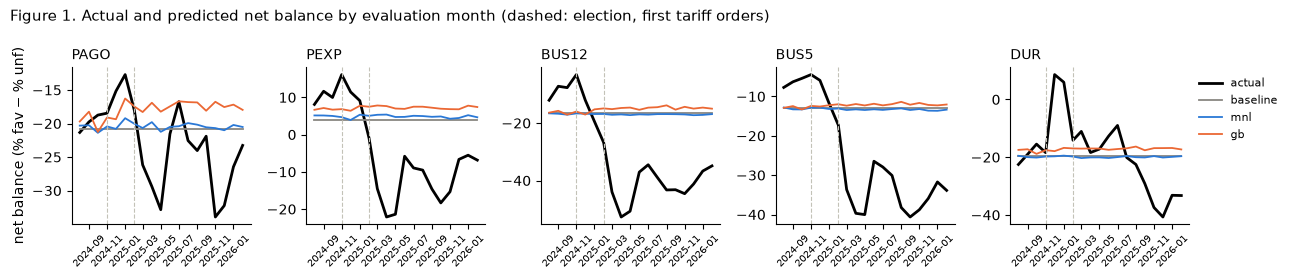

In [14]:
key = clean.set_index('CASEID')
def net_balance(P, w, month):
    v = (P[:, 0] - P[:, 2]) * w
    return pd.Series(v).groupby(month).sum() / pd.Series(w).groupby(month).sum() * 100
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8), sharey=False)
for ax, item in zip(axes, OUTCOMES):
    for name, color in [('actual', 'black'), ('baseline', '#898781'), ('mnl', '#2a78d6'), ('gb', '#eb6834')]:
        g = pred[(pred.model == ('baseline' if name == 'actual' else name)) & (pred.item == item)]
        a = key.loc[g.CASEID]
        P = np.eye(3)[a[item].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()] if name == 'actual' else g[CLASSES].to_numpy()
        s = net_balance(P, a.WT.to_numpy(), a.YYYYMM.to_numpy())
        ax.plot(pd.to_datetime(s.index.astype(str), format='%Y%m'), s.values, color=color, lw=2 if name == 'actual' else 1.3, label=name)
    for d in ['2024-11-01', '2025-02-01']:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(item, loc='left', fontsize=10); ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('net balance (% fav − % unf)'); axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 1. Actual and predicted net balance by evaluation month (dashed: election, first tariff orders)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

Boosting's extra loss comes mostly from partisans. It is flexible enough to learn how party and survey mode combine,
but the only web interviews it learns from are the four months before the 2024 election. After the election the
partisan pattern reversed, and boosting stayed confident in the old one. The logit has no such interaction: its party
effects average the Trump and Biden years of the phone data, so it hedges and loses less. The table shows the share of
`BUS12` answers that expect good times, by party.

In [15]:
tw = train[(train.web == 1) & train.BUS12.notna()]
ev = key.loc[pred[(pred.item == 'BUS12') & (pred.model == 'baseline')].CASEID]
fav = lambda d, v: np.average(v, weights=d.WT)
rows = {}
for party in ['Dem', 'Rep', 'Ind']:
    t, e = tw[tw.POLAFF == party], ev.POLAFF == party
    r = {'training web months, actual': fav(t, t.BUS12 == 'fav'), 'evaluation, actual': fav(ev[e], ev[e].BUS12 == 'fav')}
    for model in ['mnl', 'gb']:
        g = pred[(pred.item == 'BUS12') & (pred.model == model)].set_index('CASEID').loc[ev.index]
        r[f'evaluation, {model}'] = fav(ev[e], g.fav[e.to_numpy()])
    rows[party] = r
pd.DataFrame(rows).T.style.format('{:.0%}')

,"training web months, actual","evaluation, actual","evaluation, mnl","evaluation, gb"
Dem,32%,8%,16%,28%
Rep,6%,37%,22%,10%
Ind,13%,11%,16%,14%


## 4. What this run establishes

The pipeline works end to end: cleaning, encoding, tuning, fitting, prediction and both levels of scoring run from one
command, and the outputs record the commit and data that produced them. With demographics only, neither model beats a
constant prediction by more than about 2%, and the distributional error is far above the noise floor because the models
cannot follow the economy from month to month. The next run adds state variables (inflation, unemployment, the
interest rate and the president's party) and a party × president term, which should let both models follow those
movements and the partisan reversal.